<a href="https://colab.research.google.com/github/hossain8078/Machine-Learning-and-Deep-Learning/blob/main/Lab_5_Pima_Diabetes_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 5: Building a Comprehensive Pipeline
**Objective:** In this lab, you will build a complete machine learning pipeline from scratch, including preprocessing, feature selection, and a classifier. You will then use `GridSearchCV` to tune the hyperparameters of the entire pipeline.

**Dataset:** We will use the Pima Indians Diabetes Database. This is a binary classification problem where the goal is to predict whether or not a patient has diabetes.

### Instructions

1.  **Load the Dataset:** The dataset is available at this URL: `https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv`. Load it into a pandas DataFrame.
2.  **Prepare the Data:**
    - The dataset does not have column headers. You will need to add them. The feature names are: `preg`, `plas`, `pres`, `skin`, `test`, `mass`, `pedi`, `age`, `class`.
3.  **Create the Pipeline:**
    - Create a pipeline that includes:
        - A `StandardScaler` to scale the features.
        - `SelectKBest` to select the top `k` features.
        - A `RandomForestClassifier` as the final estimator.
4.  **Define the Hyperparameter Grid:**
    - Create a parameter grid to tune the `k` parameter of `SelectKBest` and the `n_estimators` and `max_depth` of the `RandomForestClassifier`.
5.  **Perform Grid Search:**
    - Use `GridSearchCV` to find the best hyperparameters for your pipeline.
6.  **Evaluate the Best Model:**
    - Print the best parameters and the best score.
    - Evaluate the best model on the test set and report the accuracy.

**Completed by: Md Alamgir Hossain**

This notebook follows the six required steps and answers all five questions. The example uses Wine and SVC; this lab instead uses the specified Pima dataset and Random Forest. Run all cells from top to bottom. Required packages: pandas, numpy, scikit-learn, matplotlib, IPython. The CSV is loaded directly from the instructor’s URL; an internet connection is required.

## 1. Load the dataset — setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
plt.rcParams.update({'figure.figsize': (8, 5), 'font.size': 11})
print('scikit-learn version:', sklearn.__version__)


scikit-learn version: 1.6.1


In [2]:
import pandas as pd
from IPython.display import display

# Load the online dataset specified in the lab instructions.
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

# The CSV has no headers; add the instructor's column names.
columns = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
df = pd.read_csv(url, header=None, names=columns)

# Confirm the dataset size and preview the first five records.
print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (768, 9)


,preg,plas,pres,skin,test,mass,pedi,age,class
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


**Note:** `header=None` ensures the first patient is retained as data. The nine supplied column names identify eight predictors and the binary target. An internet connection is required to load the online CSV.

## 2. Prepare and inspect the data

In [3]:
print('Dataset shape:', df.shape)
display(pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(), 'zero_count': df.eq(0).sum()}))
display(df['class'].value_counts().sort_index().rename_axis('class').to_frame('patients'))
assert df.shape == (768, 9)
assert set(df['class'].unique()) == {0, 1}
assert not df.isna().any().any()
X = df.drop(columns='class')
y = df['class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
print('Training rows:', len(X_train), '| Test rows:', len(X_test))


Dataset shape: (768, 9)


,dtype,missing,zero_count
preg,int64,0,111
plas,int64,0,5
pres,int64,0,35
skin,int64,0,227
test,int64,0,374
mass,float64,0,11
pedi,float64,0,0
age,int64,0,0
class,int64,0,500


,patients
class,
0,500
1,268


Training rows: 614 | Test rows: 154


**Note:** Class 0 means no diabetes and class 1 means diabetes in this dataset. `preg` = pregnancies; `plas` = plasma glucose; `pres` = diastolic blood pressure; `skin` = skinfold thickness; `test` = insulin; `mass` = BMI; `pedi` = diabetes pedigree function; `age` = age. The stratified 80/20 split preserves class proportions. The test set is reserved until the search finishes.

**Data limitation and choice:** There are no explicit NaN values, but zeros in glucose, blood pressure, skinfold thickness, insulin, and BMI can represent missing measurements. This required three-step pipeline retains the supplied values, so “no NaN” does not imply clean clinical data. A future extension could replace these zeros with NaN using a transformer and add median imputation inside the pipeline. Zero pregnancies is valid and should be retained. This is a classroom model; its results do not establish performance in other populations.

## 3. Create the required pipeline

In [4]:
pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(score_func=f_classif)),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=1))
])
print(pipeline)


Pipeline(steps=[('scaler', StandardScaler()), ('selector', SelectKBest()),
                ('classifier',
                 RandomForestClassifier(n_jobs=1, random_state=42))])


**Note:** StandardScaler learns means and standard deviations from training data. SelectKBest ranks features by their ANOVA F-statistics against the class labels. Random Forest combines decision trees to predict the class. Scaling is retained because the lab requires it; tree models generally do not need scaling, and ANOVA F-ranking is invariant to ordinary nonzero linear scaling. Keeping both transformations inside the pipeline prevents fitting them on validation or test records.

## 4. Define the hyperparameter grid

In [5]:
param_grid = {
    'selector__k': [3, 5, 8],
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 5, 10]
}
print('Parameter combinations:', len(list(ParameterGrid(param_grid))))
print('Cross-validation fits:', len(list(ParameterGrid(param_grid))) * 5)


Parameter combinations: 18
Cross-validation fits: 90


**Note:** This grid tests 18 combinations and 90 cross-validation fits, followed by one refit. `k=8` retains every predictor, providing a comparison against smaller subsets. More trees can stabilize predictions but cost time; limiting tree depth can reduce overfitting. Double underscores connect each parameter to its pipeline step. This bounded grid is practical, but cannot guarantee the best setting outside the values tested.

## 5. Perform grid search on training data

In [6]:
cv = 5  # Five-fold cross-validation, following the instructor’s example.
grid_search = GridSearchCV(pipeline, param_grid, scoring='accuracy',
                           cv=cv, n_jobs=2, refit=True, error_score='raise')
grid_search.fit(X_train, y_train)
print('Best parameters:', grid_search.best_params_)
print(f'Best mean cross-validation accuracy: {grid_search.best_score_:.4f}')
results = pd.DataFrame(grid_search.cv_results_)
display(results.sort_values(['rank_test_score']).head(5)[
    ['param_selector__k', 'param_classifier__n_estimators',
     'param_classifier__max_depth', 'mean_test_score', 'std_test_score', 'rank_test_score']])


Best parameters: {'classifier__max_depth': 10, 'classifier__n_estimators': 100, 'selector__k': 8}
Best mean cross-validation accuracy: 0.7769


,param_selector__k,param_classifier__n_estimators,param_classifier__max_depth,mean_test_score,std_test_score,rank_test_score
14,8,100,10,0.776889,0.042189,1
17,8,200,10,0.776889,0.044029,1
9,3,200,5,0.775330,0.032307,3
8,8,100,5,0.770425,0.020845,4
6,3,100,5,0.768812,0.034668,5


**Note:** Each fold fits scaling, feature selection, and the forest using only its training portion. Validation folds are transformed using those fitted steps. Accuracy matches the lab objective, while stratification keeps each fold representative of both classes. `best_score_` is the mean validation accuracy of the winning combination, not test accuracy. `refit=True` trains that combination on all training rows. The search never receives the held-out test set.

## 6. Evaluate the best model on the held-out test set

Best parameters: {'classifier__max_depth': 10, 'classifier__n_estimators': 100, 'selector__k': 8}
Best cross-validation score: 0.7769
Test accuracy: 0.7532 (75.32%)
Majority-class baseline accuracy: 0.6494
                 precision    recall  f1-score   support

No diabetes (0)       0.80      0.83      0.81       100
   Diabetes (1)       0.66      0.61      0.63        54

       accuracy                           0.75       154
      macro avg       0.73      0.72      0.72       154
   weighted avg       0.75      0.75      0.75       154



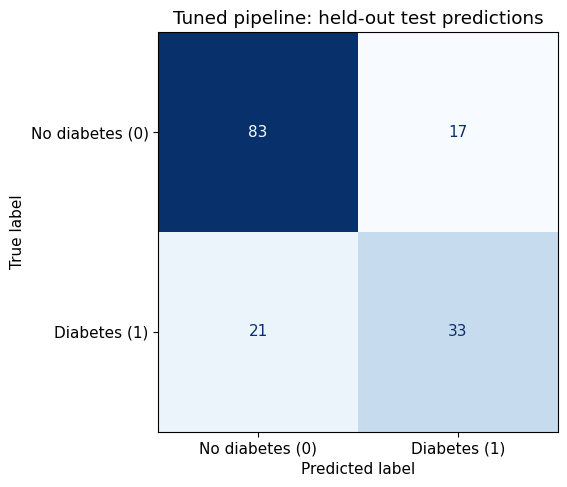

In [7]:
best_pipeline = grid_search.best_estimator_
y_pred = best_pipeline.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
baseline_accuracy = accuracy_score(y_test, baseline.predict(X_test))
print('Best parameters:', grid_search.best_params_)
print(f'Best cross-validation score: {grid_search.best_score_:.4f}')
print(f'Test accuracy: {test_accuracy:.4f} ({test_accuracy:.2%})')
print(f'Majority-class baseline accuracy: {baseline_accuracy:.4f}')
print(classification_report(y_test, y_pred, labels=[0, 1],
      target_names=['No diabetes (0)', 'Diabetes (1)'], zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['No diabetes (0)', 'Diabetes (1)']).plot(cmap='Blues', colorbar=False)
plt.title('Tuned pipeline: held-out test predictions')
plt.tight_layout()
plt.show()


**Note:** Accuracy measures the proportion of correct test predictions. Precision, recall, and F1-score provide class-specific context because the class distribution is unequal. In the confusion matrix, rows are actual classes and columns are predicted classes; the lower-left cell counts diabetes cases missed by the model. The majority-class baseline helps assess whether the model adds value beyond always predicting the common class.

### Selected features and result interpretation

In [8]:
selector = best_pipeline.named_steps['selector']
selected = X.columns[selector.get_support()].tolist()
feature_table = pd.DataFrame({'feature': X.columns, 'ANOVA F-score': selector.scores_,
                               'selected': selector.get_support()}).sort_values('ANOVA F-score', ascending=False)
display(feature_table.round(3))
forest_importance = pd.Series(best_pipeline.named_steps['classifier'].feature_importances_,
                               index=selected).sort_values(ascending=False)
display(forest_importance.rename('Random Forest importance').to_frame().round(4))
tn, fp, fn, tp = cm.ravel()
display(Markdown(
    f"**Result summary:** The dataset contains {len(df)} records and {X.shape[1]} predictors; "
    f"{len(X_train)} records were used for training and {len(X_test)} for testing. "
    f"The chosen parameters are `{grid_search.best_params_}`. "
    f"Mean cross-validation accuracy is **{grid_search.best_score_:.2%}**, and held-out accuracy is "
    f"**{test_accuracy:.2%}** ({int(tn+tp)}/{len(y_test)} correct), compared with "
    f"**{baseline_accuracy:.2%}** for the baseline. Selected features: **{', '.join(selected)}**. "
    f"The test predictions include {tn} true negatives, {tp} true positives, "
    f"{fp} false positives, and {fn} false negatives. "
    f"The largest forest importance among retained features belongs to **{forest_importance.index[0]}**. "
    "These associations do not establish causation, and a single held-out split is an uncertain estimate of future performance."))


,feature,ANOVA F-score,selected
1,plas,182.555,True
5,mass,61.160,True
7,age,37.630,True
0,preg,27.723,True
6,pedi,17.195,True
4,test,16.957,True
3,skin,5.431,True
2,pres,4.182,True


,Random Forest importance
plas,0.2884
mass,0.1680
pedi,0.1210
age,0.1209
preg,0.0830
pres,0.0785
test,0.0729
skin,0.0672


**Result summary:** The dataset contains 768 records and 8 predictors; 614 records were used for training and 154 for testing. The chosen parameters are `{'classifier__max_depth': 10, 'classifier__n_estimators': 100, 'selector__k': 8}`. Mean cross-validation accuracy is **77.69%**, and held-out accuracy is **75.32%** (116/154 correct), compared with **64.94%** for the baseline. Selected features: **preg, plas, pres, skin, test, mass, pedi, age**. The test predictions include 83 true negatives, 33 true positives, 17 false positives, and 21 false negatives. The largest forest importance among retained features belongs to **plas**. These associations do not establish causation, and a single held-out split is an uncertain estimate of future performance.

**Note:** The feature mask comes from the final refitted selector, so the listed features match the evaluated model. ANOVA scores describe individual feature association with the target; forest importance describes their use within the fitted trees. Impurity-based importance may favour some predictors and should not be interpreted as a clinical explanation. Results can vary slightly across scikit-learn versions.

## Lab Questions: Understanding Pipelines

1.  **Purpose of Pipelines:** Explain in your own words why machine learning pipelines are a valuable tool in the data science workflow. What problems do they help solve?
2.  **Data Leakage:** How does placing `StandardScaler` and `SelectKBest` *inside* a `Pipeline` before `GridSearchCV` help prevent data leakage? Describe a scenario where data leakage could occur if these steps were performed outside the pipeline.
3.  **Hyperparameter Tuning with Pipelines:** In this lab, you tuned hyperparameters for both `SelectKBest` (`k`) and `RandomForestClassifier` (`n_estimators`, `max_depth`) simultaneously using `GridSearchCV`. What is the advantage of doing this within a pipeline compared to tuning each component separately?
4.  **Components of Your Pipeline:** Identify each component of the pipeline you built in this lab and briefly describe its role in the overall machine learning process.
5.  **Extensibility:** If you wanted to add another preprocessing step, such as PCA, to your current workflow, how would you integrate it using the pipeline structure? What would be the benefit of doing so?

### 1. Purpose of pipelines
A pipeline keeps preprocessing, feature selection, and prediction in one ordered workflow. I can fit the whole process once and use it consistently for new records. This reduces repeated code, forgotten transformations, and mismatched training and prediction steps. It also makes the workflow easier to reproduce and tune.

### 2. Preventing data leakage
GridSearchCV clones and fits the complete pipeline separately within each training fold. StandardScaler therefore learns its means and standard deviations only from that fold, and SelectKBest uses only that fold's features and labels. The validation fold contributes neither scaling statistics nor feature selection decisions. For example, selecting features using all records before cross-validation would let validation labels influence which predictors are retained, making the validation result overly optimistic. Scaling the full dataset before the train/test split would also use information about the test distribution. The pipeline still needs to be fitted only on the training set, as done here.

### 3. Tuning components together
The best forest settings may depend on the number of selected features. Joint tuning evaluates combinations of feature counts, numbers of trees, and tree depths using the same folds. Tuning each component separately and fixing its choice too early could miss a stronger combination. The pipeline also ensures each candidate's preprocessing and selection are refitted correctly during validation.

### 4. Components of this pipeline
- **StandardScaler:** Centres each feature and scales it using training means and standard deviations.
- **SelectKBest with f_classif:** Selects the requested number of predictors based on ANOVA F-statistics for the target classes.
- **RandomForestClassifier:** Fits multiple randomized decision trees and combines their class probabilities to classify each record.

GridSearchCV wraps this pipeline to choose hyperparameters; it is not a transformation step inside it.

### 5. Extending the pipeline with PCA
I could insert PCA after scaling and feature selection and before the forest, then include `pca__n_components` in the parameter grid. Each fold would learn its own PCA transformation without seeing validation observations. PCA creates combinations of features, whereas SelectKBest keeps original features. Using both may be redundant, so I would justify the extra complexity and compare it using training cross-validation before touching a final test set.